# Privacy-Aware Android App Permission Management
## Borda-Garrett Ranking + Association Rule Mining + Reinforcement Learning

**Category focus:** `Games`

## 2. Imports and Configuration

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import os
import json
import random
import itertools

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy.stats import norm

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import chi2, mutual_info_classif
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, fbeta_score,
    roc_auc_score, average_precision_score, classification_report, confusion_matrix
)

try:
    import lightgbm as lgb
    HAS_LGB = True
except ImportError:
    HAS_LGB = False

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
print("LightGBM available:", HAS_LGB)

LightGBM available: True


In [23]:
# ---------------------------------------------------------------
# Reproducibility
# ---------------------------------------------------------------
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

# ---------------------------------------------------------------
# Project configuration
# ---------------------------------------------------------------
CATEGORY = "Games"
# The raw `Category` column has no literal "Games" value. It has six game genres, which are
# mapped explicitly onto the broad project category (Section 6). Nothing is fabricated.
CATEGORY_RAW_VALUES = ["Arcade & Action", "Brain & Puzzle", "Casual",
                       "Cards & Casino", "Racing", "Sports Games"]

DATA_PATH = "Android_Permission.csv"          # pandas reads the .gz directly
WEIGHTS_PATH = "combined_weights_games.csv"   # written in Section 9 from TRAIN data only
REFERENCE_WEIGHTS_PATH = "combined_weights_social_communication.csv"  # optional, comparison only
OUTPUT_DIR = "results_RL_Games"
os.makedirs(OUTPUT_DIR, exist_ok=True)

TOP_K = 12

METADATA_FEATURES = ["Number of ratings", "Dangerous permissions count", "Safe permissions count"]

MIN_RAW_PERMISSION_SUPPORT = 0.005   # Games has ~4.9k training apps, so 0.5% = ~25 apps
SMOTE_TARGET_RATIO = 1.0
N_CV_FOLDS = 5

# ---- Precision focus --------------------------------------------------------
# Final threshold = most accurate threshold on VALIDATION whose bootstrap-lower-bound precision >= PRECISION_TARGET.
PRECISION_TARGET = 0.85
FALLBACK_BETA = 0.5          # F-beta used if no threshold reaches the target (beta<1 favours precision)
MIN_RECALL_FLOOR = 0.40      # guard so the constraint can't be met by flagging only a handful of apps
THRESH_N_BOOT = 500          # bootstrap resamples of VALIDATION used to get a conservative precision estimate
THRESH_PRECISION_QUANTILE = 0.10   # the 10th-percentile precision must clear PRECISION_TARGET

# Association rule mining thresholds (not relaxed to manufacture rules)
MIN_SUPPORT = 0.05
MIN_CONFIDENCE = 0.65
MIN_LIFT = 1.05

COEF_CANDIDATES = [
    (0.60, 0.25, 0.15),
    (0.70, 0.20, 0.10),
    (0.50, 0.30, 0.20),
    (0.45, 0.40, 0.15),
    (0.35, 0.50, 0.15),
    (0.30, 0.55, 0.15),
]

# Q-learning
QL_ALPHA = 0.1
QL_GAMMA = 0.9
QL_PASSES = 3                # episodes = QL_PASSES * len(balanced train set)
QL_EPS_START = 1.0
QL_EPS_MIN = 0.05
QL_EPS_DECAY = 0.9995

PRIVACY_LOW_THRESHOLD = 0.33
PRIVACY_HIGH_THRESHOLD = 0.67

print("CATEGORY:", CATEGORY, "<- raw Category values:", CATEGORY_RAW_VALUES)
print("TOP_K:", TOP_K, "| PRECISION_TARGET:", PRECISION_TARGET)
print("Association rule thresholds:", MIN_SUPPORT, MIN_CONFIDENCE, MIN_LIFT)
print("Reward coefficient candidates:", COEF_CANDIDATES)

CATEGORY: Games <- raw Category values: ['Arcade & Action', 'Brain & Puzzle', 'Casual', 'Cards & Casino', 'Racing', 'Sports Games']
TOP_K: 12 | PRECISION_TARGET: 0.85
Association rule thresholds: 0.05 0.65 1.05
Reward coefficient candidates: [(0.6, 0.25, 0.15), (0.7, 0.2, 0.1), (0.5, 0.3, 0.2), (0.45, 0.4, 0.15), (0.35, 0.5, 0.15), (0.3, 0.55, 0.15)]


## 3. Load Dataset

In [5]:
df = pd.read_csv(DATA_PATH, low_memory=False)
print("Dataset shape:", df.shape)
missing_counts = df.isna().sum()
print("\nMissing values (columns with >0):")
print(missing_counts[missing_counts > 0])
print("\nClass distribution (0 = Benign, 1 = Malicious):")
print(df["Class"].value_counts())
print("\nGame-genre rows in the raw data:")
print(df.loc[df["Category"].isin(CATEGORY_RAW_VALUES), "Category"].value_counts())

Dataset shape: (29999, 184)

Missing values (columns with >0):
App                              1
Description                      3
Related apps                   755
Dangerous permissions count    204
dtype: int64

Class distribution (0 = Benign, 1 = Malicious):
Class
1    20000
0     9999
Name: count, dtype: int64

Game-genre rows in the raw data:
Category
Arcade & Action    1959
Brain & Puzzle     1873
Casual             1678
Cards & Casino      881
Sports Games        341
Racing              288
Name: count, dtype: int64


## 5. Data Validation

Same 12-permission aggregation map as the Social & Communication notebook, so results are comparable
across categories. Missing columns are reported, never fabricated.

In [24]:
PERMISSION_COLUMN_MAP = {
    "Camera": ["Hardware controls : take pictures and videos (D)"],
    "Location": [
        "Your location : coarse (network-based) location (D)",
        "Your location : fine (GPS) location (D)",
        "Default : coarse (network-based) location (S)",
    ],
    "Contacts": [
        "Your personal information : read contact data (D)",
        "Your personal information : write contact data (D)",
        "Default : write contact data (S)",
        "Your accounts : contacts data in Google accounts (D)",
    ],
    "Microphone": ["Hardware controls : record audio (D)"],
    "Storage": [
        "Storage : modify/delete USB storage contents modify/delete SD card contents (D)",
        "Default : modify/delete USB storage contents modify/delete SD card contents (S)",
    ],
    "SMS": [
        "Services that cost you money : send SMS messages (D)",
        "Your messages : edit SMS or MMS (D)",
        "Your messages : read SMS or MMS (D)",
        "Your messages : receive SMS (D)",
        "Your messages : receive MMS (D)",
        "Your messages : send SMS-received broadcast (S)",
    ],
    "CallLogs": [],
    "Bluetooth": [
        "Network communication : create Bluetooth connections (D)",
        "System tools : bluetooth administration (D)",
    ],
    "Calendar": [
        "Your personal information : add or modify calendar events and send email to guests (D)",
        "Your personal information : read calendar events (D)",
    ],
    "PhoneState": [
        "Default : read phone state and identity (S)",
        "Phone calls : read phone state and identity (D)",
    ],
    "Internet": [
        "Default : full Internet access (S)",
        "Network communication : full Internet access (D)",
    ],
    "ReadPhoneNumbers": [],
}
PERMISSION_NAMES = list(PERMISSION_COLUMN_MAP.keys())

missing_report = {k: [c for c in v if c not in df.columns] for k, v in PERMISSION_COLUMN_MAP.items()}
missing_report = {k: v for k, v in missing_report.items() if v}
print("Missing mapped columns:", missing_report if missing_report else "none")
print("Permissions with NO raw column in this dataset (constant 0):",
      [p for p, c in PERMISSION_COLUMN_MAP.items() if len(c) == 0])

Missing mapped columns: none
Permissions with NO raw column in this dataset (constant 0): ['CallLogs', 'ReadPhoneNumbers']


## 6. Category Filtering

In [25]:
df["BroadCategory"] = np.where(df["Category"].isin(CATEGORY_RAW_VALUES), CATEGORY, "Other")
print(df["BroadCategory"].value_counts())

cat_df = df[df["BroadCategory"] == CATEGORY].copy().reset_index(drop=True)
print(f"\nApps in category '{CATEGORY}':", len(cat_df))
print("Benign  (Class=0):", (cat_df["Class"] == 0).sum())
print("Malicious (Class=1):", (cat_df["Class"] == 1).sum())
print("\nMalicious rate by genre:")
print(cat_df.groupby("Category")["Class"].agg(["count", "mean"]).round(3))

BroadCategory
Other    22979
Games     7020
Name: count, dtype: int64

Apps in category 'Games': 7020
Benign  (Class=0): 3078
Malicious (Class=1): 3942

Malicious rate by genre:
                 count   mean
Category                     
Arcade & Action   1959  0.607
Brain & Puzzle    1873  0.636
Cards & Casino     881  0.321
Casual            1678  0.487
Racing             288  0.722
Sports Games       341  0.739


## 7. Permission Matrix + Feature Engineering

12 aggregated permission flags (RL-visible), raw permission columns (classifier-only), metadata,
and engineered features. All engineered features are derived from existing columns.

In [ ]:
def build_permission_matrix(source_df, colmap):
    out = {}
    for perm, cols in colmap.items():
        present = [c for c in cols if c in source_df.columns]
        out[perm] = ((source_df[present].apply(pd.to_numeric, errors="coerce").fillna(0).sum(axis=1) > 0)
                     .astype(int) if present else pd.Series(0, index=source_df.index))
    return pd.DataFrame(out)

perm_feats = build_permission_matrix(cat_df, PERMISSION_COLUMN_MAP)

parts = {
    "App": cat_df["App"].fillna("").values,
    "Category": cat_df["Category"].values
}

# Add permission-level aggregated features
for p in PERMISSION_NAMES:
    parts[p] = perm_feats[p].values

# Add ONLY original metadata features here
BASE_METADATA_FEATURES = [
    "Dangerous permissions count",
    "Safe permissions count",
    "Number of ratings"
]

for m in BASE_METADATA_FEATURES:
    if m in cat_df.columns:
        parts[m] = pd.to_numeric(
            cat_df[m], errors="coerce"
        ).fillna(0).values

permission_matrix = pd.DataFrame(parts)

# --- Engineered metadata ---------------------------------------------------------------
permission_matrix["PermissionCount"] = permission_matrix[PERMISSION_NAMES].sum(axis=1)
_d = permission_matrix["Dangerous permissions count"].astype(float)
_s = permission_matrix["Safe permissions count"].astype(float)
permission_matrix["DangerousToSafeRatio"] = (_d / (_d + _s + 1e-6)).clip(0, 1)
permission_matrix["LogNumRatings"] = np.log1p(permission_matrix["Number of ratings"].clip(lower=0))
permission_matrix["DescriptionLength"] = cat_df["Description"].fillna("").str.len().values

GENRE_FEATURES = [f"Genre_{g}" for g in CATEGORY_RAW_VALUES]
for g, col in zip(CATEGORY_RAW_VALUES, GENRE_FEATURES):
    permission_matrix[col] = (permission_matrix["Category"] == g).astype(int)

ENGINEERED_METADATA_FEATURES = ["PermissionCount", "DangerousToSafeRatio", "LogNumRatings", "DescriptionLength"]
METADATA_FEATURES = METADATA_FEATURES + ENGINEERED_METADATA_FEATURES + GENRE_FEATURES

# --- Raw permission columns for the classifier -----------------------------------------
NON_PERMISSION_COLUMNS = {
    "App", "Package", "Category", "BroadCategory", "Description", "Related apps",
    "Rating", "Number of ratings", "Price",
    "Dangerous permissions count", "Safe permissions count", "Class",
}
RAW_PERMISSION_COLUMNS_ALL = [c for c in df.columns if c not in NON_PERMISSION_COLUMNS]
raw_block = cat_df[RAW_PERMISSION_COLUMNS_ALL].apply(pd.to_numeric, errors="coerce").fillna(0).astype(int)
permission_matrix = pd.concat([permission_matrix, raw_block.reset_index(drop=True)], axis=1)

# Text used for DescriptionTextRisk (Section 11b). Kept in a side array, not a model feature itself.
APP_TEXT = (cat_df["App"].fillna("") + " . " + cat_df["Description"].fillna("")).values

permission_matrix["LabelEncoded"] = cat_df["Class"].astype(int).values
permission_matrix["uid"] = np.arange(len(permission_matrix))

RAW_TO_AGG = {c: perm for perm, cols in PERMISSION_COLUMN_MAP.items() for c in cols}

print("permission_matrix shape:", permission_matrix.shape)
print("\nPermission support (fraction of Games apps):")
print(permission_matrix[PERMISSION_NAMES].mean().round(4).sort_values(ascending=False))

permission_matrix shape: (7020, 202)

Permission support (fraction of Games apps):
Internet            0.8637
PhoneState          0.4785
Storage             0.3493
Location            0.1846
Contacts            0.0342
Camera              0.0160
SMS                 0.0110
Bluetooth           0.0095
Microphone          0.0073
Calendar            0.0001
CallLogs            0.0000
ReadPhoneNumbers    0.0000
dtype: float64


## 8. Train / Validation / Test Split (70 / 15 / 15, Stratified)

Happens **before** weight computation, rule mining, text modelling, classifier training and RL training.
Stratified on the label *and* genre so every genre is represented proportionally in each split.

In [27]:
strat_key = permission_matrix["LabelEncoded"].astype(str) + "_" + permission_matrix["Category"]
train_df, temp_df = train_test_split(permission_matrix, test_size=0.30, stratify=strat_key,
                                     random_state=RANDOM_STATE)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=strat_key.loc[temp_df.index],
                                   random_state=RANDOM_STATE)
train_df, val_df, test_df = train_df.copy(), val_df.copy(), test_df.copy()

for n, d in [("Train", train_df), ("Val", val_df), ("Test", test_df)]:
    print(f"{n:5s}: {d.shape}  malicious rate: {d['LabelEncoded'].mean():.3f}")

assert set(train_df.index).isdisjoint(val_df.index)
assert set(train_df.index).isdisjoint(test_df.index)
assert set(val_df.index).isdisjoint(test_df.index)
print("\nVerified: train / validation / test indices are mutually disjoint.")

# Classifier raw-permission features: support measured on TRAIN only
_raw_support = train_df[RAW_PERMISSION_COLUMNS_ALL].mean()
CLF_PERMISSION_FEATURES = [c for c in RAW_PERMISSION_COLUMNS_ALL
                           if train_df[c].nunique() > 1 and _raw_support[c] >= MIN_RAW_PERMISSION_SUPPORT]
print(f"\nRaw permission columns kept for classifier (support >= {MIN_RAW_PERMISSION_SUPPORT} on TRAIN):",
      len(CLF_PERMISSION_FEATURES))

Train: (4914, 202)  malicious rate: 0.562
Val  : (1053, 202)  malicious rate: 0.561
Test : (1053, 202)  malicious rate: 0.561

Verified: train / validation / test indices are mutually disjoint.

Raw permission columns kept for classifier (support >= 0.005 on TRAIN): 34



### 9b. Load & validate the Games weights file

In [28]:
weights_df = pd.read_csv(WEIGHTS_PATH)
weight_sum = weights_df["CombinedWeight"].sum()
print("Sum of CombinedWeight:", weight_sum)
if not np.isclose(weight_sum, 1.0, atol=1e-2):
    weights_df["CombinedWeight"] /= weight_sum
    print("Normalised to sum 1.")
weights_df = weights_df.sort_values("CombinedWeight", ascending=False).reset_index(drop=True)
weights_df["Rank"] = weights_df.index + 1
weight_map = dict(zip(weights_df["Permission"], weights_df["CombinedWeight"]))

if os.path.exists(REFERENCE_WEIGHTS_PATH):
    ref = pd.read_csv(REFERENCE_WEIGHTS_PATH).rename(columns={"CombinedWeight": "SocialComm_Weight"})
    weights_df = weights_df.merge(ref, on="Permission", how="left")
    print("Social & Communication weights shown for comparison only (not used).")
weights_df

Sum of CombinedWeight: 0.9999999999999993
Social & Communication weights shown for comparison only (not used).


,Permission,CombinedWeight,Rank,SocialComm_Weight
0,Internet,0.133291,1,0.105413
1,PhoneState,0.125290,2,0.100058
2,Location,0.108213,3,0.105413
3,Storage,0.095242,4,0.104215
4,Contacts,0.092651,5,0.080030
5,Camera,0.084203,6,0.100210
6,SMS,0.082001,7,0.080030
7,Microphone,0.080583,8,0.097402
8,Calendar,0.079129,9,0.084035
9,Bluetooth,0.067048,10,0.088193


## 10. Top Permission Selection (RL action space)

In [29]:
top_permissions = weights_df.head(TOP_K)["Permission"].tolist()
RL_FEATURES = top_permissions
print(f"TOP_{TOP_K} permissions for the RL state/action space:", top_permissions)
weights_df.head(TOP_K)[["Rank", "Permission", "CombinedWeight"]]

TOP_12 permissions for the RL state/action space: ['Internet', 'PhoneState', 'Location', 'Storage', 'Contacts', 'Camera', 'SMS', 'Microphone', 'Calendar', 'Bluetooth', 'CallLogs', 'ReadPhoneNumbers']


,Rank,Permission,CombinedWeight
0,1,Internet,0.133291
1,2,PhoneState,0.125290
2,3,Location,0.108213
3,4,Storage,0.095242
4,5,Contacts,0.092651
5,6,Camera,0.084203
6,7,SMS,0.082001
7,8,Microphone,0.080583
8,9,Calendar,0.079129
9,10,Bluetooth,0.067048


## 11. Association Rule Mining (TRAINING SET ONLY)

In [30]:
def mine_pairwise_rules(train_data, permissions, min_support, min_confidence, min_lift):
    n = len(train_data)
    rules = []
    for p1, p2 in itertools.combinations(permissions, 2):
        mask = (train_data[p1] == 1) & (train_data[p2] == 1)
        cnt = int(mask.sum())
        support = cnt / n
        if cnt == 0 or support < min_support:
            continue
        sub = train_data[mask]
        for cls, name in [(1, "Malicious"), (0, "Benign")]:
            conf = (sub["LabelEncoded"] == cls).mean()
            base = (train_data["LabelEncoded"] == cls).mean()
            lift = conf / base if base > 0 else np.nan
            if conf >= min_confidence and lift >= min_lift:
                rules.append({"Antecedent1": p1, "Antecedent2": p2, "Consequent": name,
                              "Support": support, "Confidence": conf, "Lift": lift,
                              "AntecedentCount": cnt})
    return pd.DataFrame(rules)

association_rules_df = mine_pairwise_rules(train_df, weights_df["Permission"], MIN_SUPPORT, MIN_CONFIDENCE, MIN_LIFT)
print(f"Rules at (support>={MIN_SUPPORT}, confidence>={MIN_CONFIDENCE}, lift>={MIN_LIFT}):",
      len(association_rules_df))

diag = []
for p1, p2 in itertools.combinations(weights_df["Permission"], 2):
    mask = (train_df[p1] == 1) & (train_df[p2] == 1)
    if mask.sum() == 0:
        continue
    sub = train_df[mask]
    for cls, name in [(1, "Malicious"), (0, "Benign")]:
        conf = (sub["LabelEncoded"] == cls).mean()
        lift = conf / (train_df["LabelEncoded"] == cls).mean()
        diag.append({"Pair": f"{p1} + {p2}", "Consequent": name, "Support": round(mask.mean(), 3),
                     "Confidence": round(conf, 3), "Lift": round(lift, 3),
                     "Passes": (conf >= MIN_CONFIDENCE) and (lift >= MIN_LIFT) and (mask.mean() >= MIN_SUPPORT)})
rule_diagnostics_df = pd.DataFrame(diag).sort_values(["Passes", "Confidence"], ascending=False)
print("\nTop pair diagnostics (incl. pairs that did not pass):")
rule_diagnostics_df.head(15)

Rules at (support>=0.05, confidence>=0.65, lift>=1.05): 0

Top pair diagnostics (incl. pairs that did not pass):


,Pair,Consequent,Support,Confidence,Lift,Passes
14,Internet + Calendar,Malicious,0.000,1.000,1.780,False
42,Location + Calendar,Malicious,0.000,1.000,1.780,False
60,Contacts + Microphone,Malicious,0.000,1.000,1.780,False
62,Contacts + Bluetooth,Malicious,0.000,1.000,1.780,False
68,SMS + Microphone,Malicious,0.001,1.000,1.780,False
70,Microphone + Bluetooth,Malicious,0.000,1.000,1.780,False
40,Location + Microphone,Malicious,0.001,0.800,1.424,False
66,Camera + Microphone,Malicious,0.001,0.800,1.424,False
52,Storage + Microphone,Malicious,0.004,0.650,1.157,False
11,Internet + SMS,Benign,0.010,0.625,1.426,False


## 11b. Description Text Risk (TRAINING SET ONLY, out-of-fold)

In [31]:
TEXT_C = 4.0
tr_pos = train_df["uid"].values
va_pos = val_df["uid"].values
te_pos = test_df["uid"].values

def make_text_model():
    return (TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=60000, sublinear_tf=True),
            LogisticRegression(C=TEXT_C, max_iter=4000))

text_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
oof = np.zeros(len(tr_pos))
y_tr_text = train_df["LabelEncoded"].values
for fold_tr, fold_va in text_cv.split(tr_pos, y_tr_text):
    vec, lr = make_text_model()
    Xf = vec.fit_transform(APP_TEXT[tr_pos[fold_tr]])       # vocabulary fit inside the fold too
    lr.fit(Xf, y_tr_text[fold_tr])
    oof[fold_va] = lr.predict_proba(vec.transform(APP_TEXT[tr_pos[fold_va]]))[:, 1]

text_vec, text_lr = make_text_model()
text_lr.fit(text_vec.fit_transform(APP_TEXT[tr_pos]), y_tr_text)

train_df["DescriptionTextRisk"] = oof
val_df["DescriptionTextRisk"] = text_lr.predict_proba(text_vec.transform(APP_TEXT[va_pos]))[:, 1]
test_df["DescriptionTextRisk"] = text_lr.predict_proba(text_vec.transform(APP_TEXT[te_pos]))[:, 1]

METADATA_FEATURES = METADATA_FEATURES + ["DescriptionTextRisk"]
print(f"Out-of-fold TRAIN AUC of text risk: {roc_auc_score(y_tr_text, oof):.4f}")
print(f"VALIDATION AUC of text risk:        {roc_auc_score(val_df['LabelEncoded'], val_df['DescriptionTextRisk']):.4f}")

Out-of-fold TRAIN AUC of text risk: 0.7921
VALIDATION AUC of text risk:        0.8264


## 12. SMOTE Balancing of the Training Set (RL training + utility estimation)

Used for RL training and utility estimation only (the classifier does its own SMOTE inside each CV fold).
Binary columns are rounded back to {0, 1}. Val/test are never touched.

In [20]:
BINARY_COLS = sorted(set(PERMISSION_NAMES) | set(CLF_PERMISSION_FEATURES) | set(GENRE_FEATURES))
smote_input_cols = [
    c for c in (
        BINARY_COLS
        + [m for m in METADATA_FEATURES if m not in GENRE_FEATURES]
    )
    if c in train_df.columns
]
X_train_raw = train_df[smote_input_cols].values.astype(float)
y_train_raw = train_df["LabelEncoded"].values

vc = pd.Series(y_train_raw).value_counts()
print("Before SMOTE:", vc.to_dict())
target = int(vc.max() * SMOTE_TARGET_RATIO)
if target > vc.min():
    X_res, y_res = SMOTE(random_state=RANDOM_STATE, sampling_strategy={vc.idxmin(): target}).fit_resample(X_train_raw, y_train_raw)
else:
    X_res, y_res = X_train_raw, y_train_raw

train_df_balanced = pd.DataFrame(X_res, columns=smote_input_cols)
train_df_balanced["LabelEncoded"] = y_res
for c in BINARY_COLS:
    train_df_balanced[c] = (train_df_balanced[c] >= 0.5).astype(int)
n_syn = len(train_df_balanced) - len(train_df)
train_df_balanced["App"] = list(train_df["App"].values) + [f"SMOTE_synthetic_{i}" for i in range(n_syn)]
print("After SMOTE:", train_df_balanced["LabelEncoded"].value_counts().to_dict(), f"({n_syn} synthetic rows)")

Before SMOTE: {1: 2760, 0: 2154}
After SMOTE: {1: 2760, 0: 2760} (606 synthetic rows)


## 13. Malicious-Risk Classifier (TRAINING SET ONLY, CV-selected by average precision)

Candidates are compared by **5-fold cross-validated average precision** on TRAIN (SMOTE inside each fold).
Validation metrics are reported only as an independent check; the test set plays no role here.

In [32]:
CLF_FEATURES = CLF_PERMISSION_FEATURES + METADATA_FEATURES
print(f"Classifier features: {len(CLF_PERMISSION_FEATURES)} raw permissions + {len(METADATA_FEATURES)} metadata = {len(CLF_FEATURES)}")

X_trainfull, y_trainfull = train_df[CLF_FEATURES].values.astype(float), train_df["LabelEncoded"].values
X_val, y_val = val_df[CLF_FEATURES].values.astype(float), val_df["LabelEncoded"].values

cv = StratifiedKFold(n_splits=N_CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)

candidate_pipelines = {
    "RandomForest": (ImbPipeline([("smote", SMOTE(random_state=RANDOM_STATE)),
                                  ("clf", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1))]),
                     {"clf__n_estimators": [500], "clf__max_depth": [None, 16], "clf__min_samples_leaf": [1, 3],
                      "clf__max_features": ["sqrt", 0.3]}),
    "HistGradientBoosting": (ImbPipeline([("smote", SMOTE(random_state=RANDOM_STATE)),
                                          ("clf", HistGradientBoostingClassifier(random_state=RANDOM_STATE))]),
                             {"clf__max_iter": [300, 600], "clf__learning_rate": [0.03, 0.06],
                              "clf__max_leaf_nodes": [15, 31], "clf__l2_regularization": [0.0, 1.0]}),
    "LogisticRegression": (ImbPipeline([("smote", SMOTE(random_state=RANDOM_STATE)),
                                        ("scale", StandardScaler()),
                                        ("clf", LogisticRegression(max_iter=5000))]),
                           {"clf__C": [0.03, 0.3, 3.0]}),
}
if HAS_LGB:
    candidate_pipelines["LightGBM"] = (
        ImbPipeline([("smote", SMOTE(random_state=RANDOM_STATE)),
                     ("clf", lgb.LGBMClassifier(random_state=RANDOM_STATE, verbose=-1, n_jobs=2))]),
        {"clf__n_estimators": [400, 800], "clf__learning_rate": [0.02, 0.05],
         "clf__num_leaves": [15, 31], "clf__subsample": [0.8], "clf__subsample_freq": [1],
         "clf__colsample_bytree": [0.7], "clf__min_child_samples": [20]})

risk_model_metrics, fitted_grids = [], {}
for name, (pipe, grid_params) in candidate_pipelines.items():
    grid = GridSearchCV(pipe, grid_params, scoring="average_precision", cv=cv, n_jobs=1, refit=True)
    grid.fit(X_trainfull, y_trainfull)
    fitted_grids[name] = grid
    vp = grid.predict_proba(X_val)[:, 1]
    vpred = (vp >= 0.5).astype(int)
    risk_model_metrics.append({
        "Model": name, "CV_AvgPrecision": grid.best_score_,
        "Val_AvgPrecision": average_precision_score(y_val, vp), "Val_AUC": roc_auc_score(y_val, vp),
        "Val_Accuracy@0.5": accuracy_score(y_val, vpred), "Val_Precision@0.5": precision_score(y_val, vpred),
        "Val_Recall@0.5": recall_score(y_val, vpred), "BestParams": grid.best_params_,
    })
    print(f"{name:22s} CV AP={grid.best_score_:.4f}  Val AP={risk_model_metrics[-1]['Val_AvgPrecision']:.4f}")

# ---- Soft-voting ensemble of the tuned candidates (evaluated with the SAME CV folds) ----------
from sklearn.ensemble import VotingClassifier
from sklearn.model_selection import cross_val_score
from sklearn.base import clone
ensemble = VotingClassifier(
    estimators=[(n, clone(g.best_estimator_)) for n, g in fitted_grids.items()], voting="soft", n_jobs=1)
ens_cv_ap = cross_val_score(ensemble, X_trainfull, y_trainfull, cv=cv, scoring="average_precision").mean()
ensemble.fit(X_trainfull, y_trainfull)
vp = ensemble.predict_proba(X_val)[:, 1]; vpred = (vp >= 0.5).astype(int)
risk_model_metrics.append({
    "Model": "SoftVotingEnsemble", "CV_AvgPrecision": ens_cv_ap,
    "Val_AvgPrecision": average_precision_score(y_val, vp), "Val_AUC": roc_auc_score(y_val, vp),
    "Val_Accuracy@0.5": accuracy_score(y_val, vpred), "Val_Precision@0.5": precision_score(y_val, vpred),
    "Val_Recall@0.5": recall_score(y_val, vpred), "BestParams": "soft vote of tuned candidates"})
print(f"{'SoftVotingEnsemble':22s} CV AP={ens_cv_ap:.4f}  Val AP={risk_model_metrics[-1]['Val_AvgPrecision']:.4f}")

class _Holder:  # uniform access for the ensemble
    def __init__(self, est): self.best_estimator_ = est
fitted_grids["SoftVotingEnsemble"] = _Holder(ensemble)

risk_model_metrics_df = pd.DataFrame(risk_model_metrics).sort_values("CV_AvgPrecision", ascending=False).reset_index(drop=True)
display(risk_model_metrics_df)

BEST_RISK_MODEL_NAME = risk_model_metrics_df.iloc[0]["Model"]
risk_model = fitted_grids[BEST_RISK_MODEL_NAME].best_estimator_
print(f"Selected risk model (by CV average precision on TRAIN): {BEST_RISK_MODEL_NAME}")
print("Best hyperparameters:", risk_model_metrics_df.iloc[0]["BestParams"])

try:
    _est = risk_model if hasattr(risk_model, "named_steps") else fitted_grids["RandomForest"].best_estimator_
    imp = _est.named_steps["clf"].feature_importances_
    imp = imp / imp.sum()
    print("\nTop 15 features by importance (RandomForest component if an ensemble was selected):")
    for i in np.argsort(imp)[::-1][:15]:
        print(f"   {CLF_FEATURES[i][:72]:72s} {imp[i]:.4f}")
except (AttributeError, KeyError):
    pass

def predict_malicious_proba(X2d):
    return risk_model.predict_proba(np.asarray(X2d, dtype=float))[:, 1]

Classifier features: 34 raw permissions + 14 metadata = 48
RandomForest           CV AP=0.9180  Val AP=0.8963
HistGradientBoosting   CV AP=0.9052  Val AP=0.9058
LogisticRegression     CV AP=0.8810  Val AP=0.8886
LightGBM               CV AP=0.9047  Val AP=0.9122
SoftVotingEnsemble     CV AP=0.9107  Val AP=0.9090


,Model,CV_AvgPrecision,Val_AvgPrecision,Val_AUC,Val_Accuracy@0.5,Val_Precision@0.5,Val_Recall@0.5,BestParams
0,RandomForest,0.918007,0.896300,0.859875,0.778727,0.840304,0.747885,"{'clf__max_depth': None, 'clf__max_features': ..."
1,SoftVotingEnsemble,0.910735,0.909016,0.876226,0.772080,0.847525,0.724196,soft vote of tuned candidates
2,HistGradientBoosting,0.905180,0.905821,0.871624,0.778727,0.841603,0.746193,"{'clf__l2_regularization': 1.0, 'clf__learning..."
3,LightGBM,0.904659,0.912172,0.881337,0.771130,0.852823,0.715736,"{'clf__colsample_bytree': 0.7, 'clf__learning_..."
4,LogisticRegression,0.881007,0.888595,0.851677,0.777778,0.833645,0.754653,{'clf__C': 0.03}


Selected risk model (by CV average precision on TRAIN): RandomForest
Best hyperparameters: {'clf__max_depth': None, 'clf__max_features': 0.3, 'clf__min_samples_leaf': 1, 'clf__n_estimators': 500}

Top 15 features by importance (RandomForest component if an ensemble was selected):
   DescriptionTextRisk                                                      0.2927
   Number of ratings                                                        0.1551
   LogNumRatings                                                            0.1444
   DescriptionLength                                                        0.0995
   DangerousToSafeRatio                                                     0.0353
   Safe permissions count                                                   0.0265
   Genre_Cards & Casino                                                     0.0265
   Dangerous permissions count                                              0.0227
   PermissionCount                                     

## 14. Evidence-Based Utility (TRAINING SET ONLY)

`Utility(perm) = P(perm | Benign) / max P(perm | Benign)` over the TOP_K permissions.

In [33]:
benign_train = train_df_balanced[train_df_balanced["LabelEncoded"] == 0]
p_perm_given_benign = {p: float(benign_train[p].mean()) for p in RL_FEATURES}
util_max = max(p_perm_given_benign.values()) or 1.0
utility_map = {p: p_perm_given_benign[p] / util_max for p in RL_FEATURES}
utility_table = pd.DataFrame({
    "Permission": RL_FEATURES,
    "P_Present_Given_Benign": [p_perm_given_benign[p] for p in RL_FEATURES],
    "P_Present_Given_AllApps": [float(train_df_balanced[p].mean()) for p in RL_FEATURES],
    "UtilityNormalized": [utility_map[p] for p in RL_FEATURES],
}).sort_values("UtilityNormalized", ascending=False).reset_index(drop=True)
utility_table

,Permission,P_Present_Given_Benign,P_Present_Given_AllApps,UtilityNormalized
0,Internet,0.925362,0.869384,1.000000
1,PhoneState,0.538043,0.485145,0.581441
2,Storage,0.348188,0.345833,0.376273
3,Location,0.209058,0.184783,0.225920
4,Contacts,0.035507,0.033333,0.038371
5,Camera,0.018478,0.015217,0.019969
6,SMS,0.013768,0.010145,0.014879
7,Bluetooth,0.009058,0.009239,0.009789
8,Microphone,0.005435,0.006159,0.005873
9,Calendar,0.000000,0.000181,0.000000


## 15. Privacy Risk Model

| Component | Formula |
|---|---|
| `IndividualRisk(perm)` | `CombinedWeight(perm) / max CombinedWeight over TOP_K` |
| `ClassifierRisk(granted)` | `P(Malicious \| full permission context + metadata)`; denying an aggregate zeroes all its raw sub-columns |
| `InteractionRisk(granted)` | sum of `RuleEvidenceNorm` of triggered malicious rules, capped at 1 |

Classifier risk is **cached**: for each app, every subset of its requested TOP_K permissions is scored in one
batch. The cache key is the exact feature vector, so values are identical to calling the model per step.

In [35]:
# ============================================================
# RL + Classifier Risk Utilities
# ============================================================

# ------------------------------------------------------------
# 1. Maximum RL permission weight
# ------------------------------------------------------------

MAX_WEIGHT = max(
    weight_map.get(p, 0.0)
    for p in RL_FEATURES
)

def individual_risk_normalized(perm):
    """
    Normalize the individual permission risk to [0, 1]
    using the maximum weight among RL_FEATURES.
    """
    if MAX_WEIGHT == 0:
        return 0.0

    return weight_map.get(perm, 0.0) / MAX_WEIGHT


# ------------------------------------------------------------
# 2. Map classifier-level permission features to aggregated
#    permission names
# ------------------------------------------------------------

_CLF_PERM_AGG = [
    RAW_TO_AGG.get(p)
    for p in CLF_PERMISSION_FEATURES
]


# ------------------------------------------------------------
# 3. Classifier prediction cache
# ------------------------------------------------------------

_CLS_CACHE = {}


# ------------------------------------------------------------
# 4. Build classifier feature vector
# ------------------------------------------------------------

def _feature_vector(granted, requested, metadata):

    perm_part = []

    for p, agg in zip(
        CLF_PERMISSION_FEATURES,
        _CLF_PERM_AGG
    ):

        if agg is not None and agg in RL_FEATURES:

            # Permission is considered available to classifier
            # only if it was requested AND granted.
            value = (
                requested.get(p, 0)
                if granted.get(agg, 0) == 1
                else 0
            )

        else:

            value = requested.get(p, 0)

        perm_part.append(float(value))

    return np.asarray(
        perm_part + list(metadata),
        dtype=float
    )


# ------------------------------------------------------------
# 5. Classifier risk
# ------------------------------------------------------------

def classifier_risk(
    granted,
    requested,
    metadata
):

    v = _feature_vector(
        granted,
        requested,
        metadata
    )

    key = v.tobytes()

    if key not in _CLS_CACHE:

        _CLS_CACHE[key] = float(
            predict_malicious_proba(
                v.reshape(1, -1)
            )[0]
        )

    return _CLS_CACHE[key]


# ------------------------------------------------------------
# 6. Interaction risk from association rules
# ------------------------------------------------------------

def interaction_risk(granted_set):

    if (
        not RULE_LOOKUP
        or len(granted_set) < 2
    ):
        return 0.0, []

    total = 0.0
    triggered_rules = []

    for pair, ev in RULE_LOOKUP.items():

        if pair.issubset(granted_set):

            total += ev

            triggered_rules.append(
                tuple(sorted(pair))
            )

    return (
        min(total, 1.0),
        triggered_rules
    )


# ------------------------------------------------------------
# 7. Requested permission vector
# ------------------------------------------------------------

def make_requested_vector(row):

    d = {}

    # Aggregated permission features
    for p in PERMISSION_NAMES:

        if p in row.index:

            value = row[p]

            # Handle duplicate DataFrame columns
            if isinstance(value, pd.Series):
                value = value.iloc[0]

            value = pd.to_numeric(
                value,
                errors="coerce"
            )

            d[p] = (
                0
                if pd.isna(value)
                else int(value)
            )

        else:

            d[p] = 0

    # Raw classifier permission features
    for p in CLF_PERMISSION_FEATURES:

        if p in row.index:

            value = row[p]

            # Handle duplicate DataFrame columns
            if isinstance(value, pd.Series):
                value = value.iloc[0]

            value = pd.to_numeric(
                value,
                errors="coerce"
            )

            d[p] = (
                0
                if pd.isna(value)
                else int(value)
            )

        else:

            d[p] = 0

    return d


# ------------------------------------------------------------
# 8. Metadata vector
# ------------------------------------------------------------

def make_metadata_vector(row):

    metadata = []

    for m in METADATA_FEATURES:

        # If the feature is completely absent
        if m not in row.index:

            # Temporary fallback so the current pipeline
            # does not crash.
            metadata.append(0.0)
            continue

        value = row[m]

        # IMPORTANT:
        # If the DataFrame contains duplicate column names,
        # row[m] becomes a Series instead of a scalar.
        if isinstance(value, pd.Series):

            # Take the first duplicate occurrence.
            value = value.iloc[0]

        value = pd.to_numeric(
            value,
            errors="coerce"
        )

        if pd.isna(value):

            value = 0.0

        metadata.append(
            float(value)
        )

    return np.asarray(
        metadata,
        dtype=float
    )


# ------------------------------------------------------------
# 9. Warm classifier cache
# ------------------------------------------------------------

def warm_classifier_cache(data_df):

    """
    Batch-score every combination of granted TOP_K
    permissions for every application.

    The resulting probabilities are stored in _CLS_CACHE.
    """

    vecs = []
    keys = []

    for _, row in data_df.iterrows():

        # ----------------------------------------------------
        # Requested permissions + metadata
        # ----------------------------------------------------

        req = make_requested_vector(row)

        meta = make_metadata_vector(row)

        # ----------------------------------------------------
        # Permissions from TOP_K that this app actually requests
        # ----------------------------------------------------

        req_perms = [
            p
            for p in RL_FEATURES
            if req.get(p, 0) == 1
        ]

        # ----------------------------------------------------
        # Generate every possible granted subset
        # ----------------------------------------------------

        for r in range(
            len(req_perms) + 1
        ):

            for subset in itertools.combinations(
                req_perms,
                r
            ):

                # Granted permission dictionary
                g = {
                    p: (
                        1
                        if p in subset
                        else 0
                    )
                    for p in RL_FEATURES
                }

                # Build classifier input
                v = _feature_vector(
                    g,
                    req,
                    meta
                )

                # Use vector bytes as cache key
                k = v.tobytes()

                # Avoid duplicate prediction
                if k not in _CLS_CACHE:

                    vecs.append(v)
                    keys.append(k)

    # --------------------------------------------------------
    # Batch prediction
    # --------------------------------------------------------

    if vecs:

        X_batch = np.vstack(vecs)

        probs = predict_malicious_proba(
            X_batch
        )

        _CLS_CACHE.update(
            dict(
                zip(
                    keys,
                    map(float, probs)
                )
            )
        )

    return len(vecs)


# ============================================================
# 10. Remove duplicate DataFrame columns temporarily
# ============================================================

# This does NOT modify METADATA_FEATURES.
# It only prevents pandas from returning a Series when
# row[column_name] encounters duplicate column names.

train_df_balanced = train_df_balanced.loc[
    :,
    ~train_df_balanced.columns.duplicated()
]

val_df = val_df.loc[
    :,
    ~val_df.columns.duplicated()
]

test_df = test_df.loc[
    :,
    ~test_df.columns.duplicated()
]


# ============================================================
# 11. Clear old classifier cache
# ============================================================

_CLS_CACHE.clear()


# ============================================================
# 12. Warm classifier cache
# ============================================================

for name, d in [
    ("train_balanced", train_df_balanced),
    ("val", val_df),
    ("test", test_df)
]:

    new_vectors = warm_classifier_cache(d)

    print(
        f"Cached classifier risk for {name}: "
        f"{new_vectors} new vectors"
    )


# ============================================================
# 13. Display normalized individual permission risk
# ============================================================

print(
    "\nNormalized individual risk per TOP_K permission:"
)

for p in RL_FEATURES:

    print(
        f"   {p:20s} -> "
        f"{individual_risk_normalized(p):.4f}"
    )


# ============================================================
# 14. Diagnostic information
# ============================================================

print(
    "\nTotal classifier cache size:",
    len(_CLS_CACHE)
)

print(
    "Number of RL features:",
    len(RL_FEATURES)
)

print(
    "Number of classifier permission features:",
    len(CLF_PERMISSION_FEATURES)
)

print(
    "Number of metadata features:",
    len(METADATA_FEATURES)
)

Cached classifier risk for train_balanced: 30996 new vectors
Cached classifier risk for val: 6064 new vectors
Cached classifier risk for test: 5993 new vectors

Normalized individual risk per TOP_K permission:
   Internet             -> 1.0000
   PhoneState           -> 0.9400
   Location             -> 0.8119
   Storage              -> 0.7145
   Contacts             -> 0.6951
   Camera               -> 0.6317
   SMS                  -> 0.6152
   Microphone           -> 0.6046
   Calendar             -> 0.5937
   Bluetooth            -> 0.5030
   CallLogs             -> 0.1964
   ReadPhoneNumbers     -> 0.1964

Total classifier cache size: 41117
Number of RL features: 12
Number of classifier permission features: 34
Number of metadata features: 14


## 16. RL Environment

Sequential Allow/Deny over the TOP_K permissions in Borda-Garrett rank order. State = `(step, granted_mask)`.
The environment is built from the request vector only — never the `Class` label.

```
ALLOW:  reward = ALPHA*Utility - BETA*(0.5*IndRiskNorm + 0.5*ClassifierRisk) - GAMMA*InteractionRisk
DENY:   reward = -(ALPHA*Utility) * denial_cost      (denial_cost = 0.5)
```

In [36]:
class PermissionEnv:
    def __init__(self, requested_vector, alpha, beta, gamma, metadata_vector, denial_cost=0.5):
        self.requested, self.metadata = requested_vector, metadata_vector
        self.order = RL_FEATURES
        self.alpha, self.beta, self.gamma, self.denial_cost = alpha, beta, gamma, denial_cost
        self.reset()

    def reset(self):
        self.step_idx, self.done = 0, False
        self.granted = {p: 0 for p in self.order}
        return self._state()

    def _state(self):
        return (self.step_idx, tuple(self.granted[p] for p in self.order))

    def step(self, action):
        perm = self.order[self.step_idx]
        if self.requested.get(perm, 0) == 0:
            reward = 0.0
        else:
            util = utility_map[perm]
            if action == 1:
                self.granted[perm] = 1
                gset = frozenset(p for p in self.order if self.granted[p])
                cls_r = classifier_risk(self.granted, self.requested, self.metadata)
                int_r, _ = interaction_risk(gset)
                reward = self.alpha * util - self.beta * (0.5 * individual_risk_normalized(perm) + 0.5 * cls_r) - self.gamma * int_r
            else:
                self.granted[perm] = 0
                reward = -(self.alpha * util) * self.denial_cost
        self.step_idx += 1
        self.done = self.step_idx >= len(self.order)
        return self._state(), reward, self.done, {}

# Sanity check: Allow-all must beat Deny-all for a fully-requested probe app
probe_req = {p: 1 for p in PERMISSION_NAMES}
probe_req.update({p: 0 for p in CLF_PERMISSION_FEATURES})
for p in CLF_PERMISSION_FEATURES:
    if RAW_TO_AGG.get(p) in RL_FEATURES:
        probe_req[p] = 1
probe_meta = [float(train_df_balanced[m].mean()) if m in train_df_balanced else float(train_df[m].mean()) for m in METADATA_FEATURES]
totals = {}
for a in (1, 0):
    env = PermissionEnv(probe_req, 0.6, 0.25, 0.15, probe_meta); env.reset(); tot, done = 0.0, False
    while not done:
        _, r, done, _ = env.step(a); tot += r
    totals[a] = tot
print("Allow-everything reward:", round(totals[1], 4), "| Deny-everything reward:", round(totals[0], 4))
assert totals[1] > totals[0], "Reward design has collapsed toward deny-all!"
print("PASS: reward design does not collapse to a trivial deny-all policy.")

Allow-everything reward: 0.0255 | Deny-everything reward: -0.6818
PASS: reward design does not collapse to a trivial deny-all policy.


## 17. Q-Learning Agent (Tabular)

In [37]:
def train_q_learning(data_df, a_c, b_c, g_c, n_passes=QL_PASSES, lr=QL_ALPHA, discount=QL_GAMMA,
                     eps_start=QL_EPS_START, eps_min=QL_EPS_MIN, eps_decay=QL_EPS_DECAY, seed=RANDOM_STATE):
    rng = np.random.RandomState(seed)
    Q = {}
    rows = data_df.sample(frac=1.0, random_state=seed).reset_index(drop=True)   # shuffle once
    envs_in = [(make_requested_vector(r), make_metadata_vector(r)) for _, r in rows.iterrows()]
    n_rows, n_eps = len(rows), n_passes * len(rows)
    eps, hist = eps_start, []
    for ep in range(n_eps):
        req, meta = envs_in[ep % n_rows]
        env = PermissionEnv(req, a_c, b_c, g_c, meta)
        s = env.reset(); ep_r, n_allow, n_deny, done = 0.0, 0, 0, False
        while not done:
            if rng.rand() < eps:
                a = rng.randint(0, 2)
            else:
                q0, q1 = Q.get((s, 0), 0.0), Q.get((s, 1), 0.0)
                a = int(q1 > q0) if q1 != q0 else rng.randint(0, 2)
            perm = env.order[s[0]]
            s2, r, done, _ = env.step(a)
            if req.get(perm, 0) == 1:
                n_allow += a; n_deny += 1 - a
            best_next = 0.0 if done else max(Q.get((s2, 0), 0.0), Q.get((s2, 1), 0.0))
            Q[(s, a)] = Q.get((s, a), 0.0) + lr * (r + discount * best_next - Q.get((s, a), 0.0))
            ep_r += r; s = s2
        eps = max(eps_min, eps * eps_decay)
        hist.append((ep, ep_r, eps, n_allow, n_deny))
    return Q, pd.DataFrame(hist, columns=["episode", "reward", "epsilon", "n_allow", "n_deny"])

def greedy_action(Q, s):
    return 1 if Q.get((s, 1), 0.0) >= Q.get((s, 0), 0.0) else 0

## 18. RL Training (default coefficients, TRAIN)

Episodes: 16560 | Q-table entries: 744
Mean reward, first 500 episodes: 0.0654
Mean reward, last 500 episodes:  0.4402


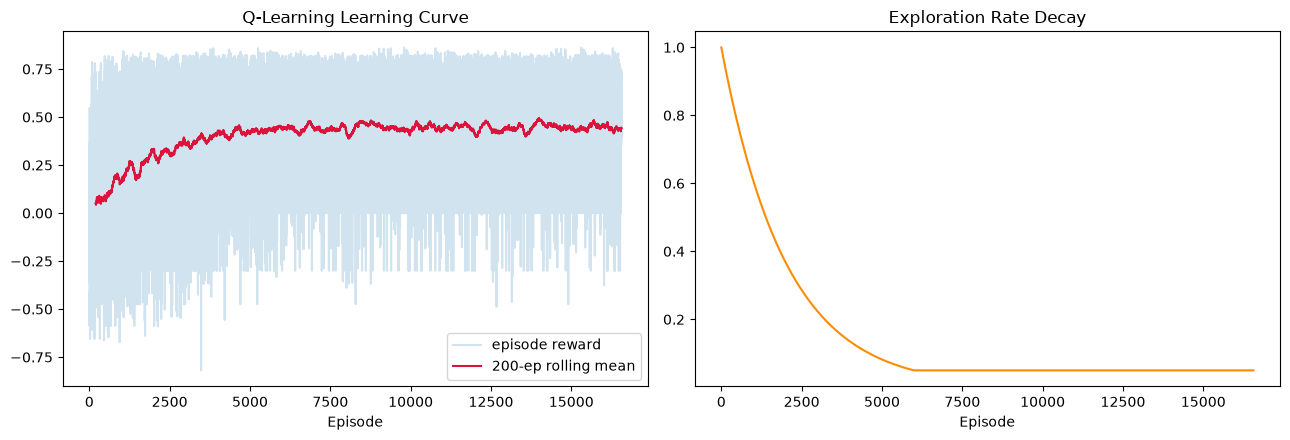

In [38]:
Q_table_default, rl_training_history = train_q_learning(train_df_balanced, 0.60, 0.25, 0.15)
print("Episodes:", len(rl_training_history), "| Q-table entries:", len(Q_table_default))
print("Mean reward, first 500 episodes:", round(rl_training_history["reward"].head(500).mean(), 4))
print("Mean reward, last 500 episodes: ", round(rl_training_history["reward"].tail(500).mean(), 4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(rl_training_history["episode"], rl_training_history["reward"], alpha=0.2, label="episode reward")
axes[0].plot(rl_training_history["episode"], rl_training_history["reward"].rolling(200).mean(), color="crimson", label="200-ep rolling mean")
axes[0].set_title("Q-Learning Learning Curve"); axes[0].set_xlabel("Episode"); axes[0].legend()
axes[1].plot(rl_training_history["episode"], rl_training_history["epsilon"], color="darkorange")
axes[1].set_title("Exploration Rate Decay"); axes[1].set_xlabel("Episode")
plt.tight_layout(); plt.savefig(os.path.join(OUTPUT_DIR, "learning_curve.png"), dpi=120); plt.show()

## 19. Validation-Based Reward-Coefficient + Threshold Selection (precision-constrained)

For each `(ALPHA, BETA, GAMMA)`: train a Q-table on TRAIN, apply it to VALIDATION, then choose the
Low/not-Low threshold as **the most accurate threshold whose bootstrap 10th-percentile precision ≥
`PRECISION_TARGET`** and recall ≥
`MIN_RECALL_FLOOR` (fallback: max F0.5). Candidates are ranked by that constrained validation accuracy,
then precision. **The test set is not used.**

In [39]:
PRIVACY_SCORE_WEIGHTS = {"individual": 0.05, "classifier": 0.90, "interaction": 0.05}

def privacy_class(score, low_thr=PRIVACY_LOW_THRESHOLD, high_thr=PRIVACY_HIGH_THRESHOLD):
    return "Low" if score <= low_thr else ("Medium" if score <= high_thr else "High")

def classification_metrics(y_true, y_pred):
    return {"Accuracy": accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred, zero_division=0),
            "Recall": recall_score(y_true, y_pred, zero_division=0),
            "F1": f1_score(y_true, y_pred, zero_division=0)}

def _score_record(row, requested, granted_dict, ep_reward=np.nan):
    granted_set = frozenset(p for p in RL_FEATURES if granted_dict.get(p, 0) == 1)
    requested_set = frozenset(p for p in RL_FEATURES if requested.get(p, 0) == 1)
    meta = make_metadata_vector(row)
    ind = np.mean([individual_risk_normalized(p) for p in granted_set]) if granted_set else 0.0
    cls_r = classifier_risk(granted_dict, requested, meta)
    int_r, trig = interaction_risk(granted_set)
    util = sum(utility_map[p] for p in granted_set) / len(requested_set) if requested_set else 0.0
    ps = float(np.clip(PRIVACY_SCORE_WEIGHTS["individual"] * ind + PRIVACY_SCORE_WEIGHTS["classifier"] * cls_r
                       + PRIVACY_SCORE_WEIGHTS["interaction"] * int_r, 0, 1))
    return {"App": row["App"], "TrueLabel": int(row["LabelEncoded"]),
            "RequestedPermissions": ";".join(sorted(requested_set)),
            "AllowedPermissions": ";".join(sorted(granted_set)),
            "DeniedPermissions": ";".join(sorted(requested_set - granted_set)),
            "NumRequested": len(requested_set), "NumAllowed": len(granted_set),
            "NumDenied": len(requested_set - granted_set),
            "IndividualRisk": ind, "MaliciousProbability": cls_r, "InteractionRisk": int_r,
            "TriggeredRules": ";".join("+".join(t) for t in trig),
            "UtilityScore": util, "PrivacyScore": ps, "RLReward": ep_reward}

def apply_policy(Q, data_df, a_c, b_c, g_c):
    recs = []
    for _, row in data_df.iterrows():
        req, meta = make_requested_vector(row), make_metadata_vector(row)
        env = PermissionEnv(req, a_c, b_c, g_c, meta); s = env.reset(); ep_r, done = 0.0, False
        while not done:
            s, r, done, _ = env.step(greedy_action(Q, s)); ep_r += r
        recs.append(_score_record(row, req, env.granted, ep_r))
    return pd.DataFrame(recs)

_BOOT_IDX_CACHE = {}
def _boot_idx(n):
    if n not in _BOOT_IDX_CACHE:
        _BOOT_IDX_CACHE[n] = np.random.RandomState(RANDOM_STATE).randint(0, n, (THRESH_N_BOOT, n))
    return _BOOT_IDX_CACHE[n]

def find_precision_threshold(scores, y_true, precision_target=PRECISION_TARGET,
                             min_recall=MIN_RECALL_FLOOR, grid=None):
    # Most accurate threshold whose BOOTSTRAP LOWER-BOUND precision (THRESH_PRECISION_QUANTILE) on
    # validation is >= target, with recall >= floor. Requiring the lower bound -- not the point
    # estimate -- to clear the target protects against picking a threshold that only looks precise
    # because of validation-sample noise. Fallback: max F-beta.
    if grid is None:
        grid = np.round(np.arange(0.20, 0.951, 0.005), 3)
    scores, y_true = np.asarray(scores), np.asarray(y_true)
    B = _boot_idx(len(y_true)); yb, sb = y_true[B], scores[B]
    rows = []
    for t in grid:
        pred = (scores > t).astype(int)
        m = classification_metrics(y_true, pred)
        m["F0.5"] = fbeta_score(y_true, pred, beta=FALLBACK_BETA, zero_division=0)
        pb = sb > t
        tp = (pb & (yb == 1)).sum(axis=1); npos = pb.sum(axis=1)
        m["PrecisionLB"] = float(np.quantile(np.where(npos > 0, tp / np.maximum(npos, 1), 0), THRESH_PRECISION_QUANTILE))
        m["Threshold"] = t
        rows.append(m)
    tab = pd.DataFrame(rows)
    ok = tab[(tab["PrecisionLB"] >= precision_target) & (tab["Recall"] >= min_recall)]
    if len(ok):
        best = ok.sort_values(["Accuracy", "Precision"], ascending=False).iloc[0]
        rule = f"max accuracy s.t. P{int(THRESH_PRECISION_QUANTILE*100)} precision>={precision_target}"
    else:
        best = tab.sort_values("F0.5", ascending=False).iloc[0]
        rule = f"fallback: max F{FALLBACK_BETA}"
    return float(best["Threshold"]), best, rule, tab

selection_records, trained_qtables, val_results_cache = [], {}, {}
for (a, b, g) in COEF_CANDIDATES:
    Q, hist = train_q_learning(train_df_balanced, a, b, g)
    trained_qtables[(a, b, g)] = (Q, hist)
    vr = apply_policy(Q, val_df, a, b, g)
    val_results_cache[(a, b, g)] = vr
    thr, best, rule, _ = find_precision_threshold(vr["PrivacyScore"].values, vr["TrueLabel"].values)
    selection_records.append({
        "Alpha": a, "Beta": b, "Gamma": g, "Threshold": thr, "Rule": rule,
        "Val_Accuracy": best["Accuracy"], "Val_Precision": best["Precision"],
        "Val_Recall": best["Recall"], "Val_F1": best["F1"], "Val_F0.5": best["F0.5"],
        "Val_PrecisionLB": best["PrecisionLB"],
        "Val_AllowRate": vr["NumAllowed"].sum() / max(vr["NumRequested"].sum(), 1),
        "Val_AvgUtility": vr["UtilityScore"].mean(), "Val_AvgPrivacyRisk": vr["PrivacyScore"].mean(),
    })

selection_df = (pd.DataFrame(selection_records)
                .assign(_meets=lambda d: d["Val_PrecisionLB"] >= PRECISION_TARGET)
                .sort_values(["_meets", "Val_Accuracy", "Val_Precision", "Val_AvgUtility"], ascending=False)
                .drop(columns="_meets").reset_index(drop=True))
display(selection_df)

BEST_ALPHA, BEST_BETA, BEST_GAMMA, BEST_THRESHOLD = selection_df.iloc[0][["Alpha", "Beta", "Gamma", "Threshold"]]
BEST_Q, BEST_HISTORY = trained_qtables[(BEST_ALPHA, BEST_BETA, BEST_GAMMA)]
print(f"Selected: ALPHA={BEST_ALPHA}, BETA={BEST_BETA}, GAMMA={BEST_GAMMA}, THRESHOLD={BEST_THRESHOLD:.3f} "
      f"(val acc={selection_df.iloc[0]['Val_Accuracy']:.4f}, val precision={selection_df.iloc[0]['Val_Precision']:.4f})")

,Alpha,Beta,Gamma,Threshold,Rule,Val_Accuracy,Val_Precision,Val_Recall,Val_F1,Val_F0.5,Val_PrecisionLB,Val_AllowRate,Val_AvgUtility,Val_AvgPrivacyRisk
0,0.30,0.55,0.15,0.495,max accuracy s.t. P10 precision>=0.85,0.780627,0.873444,0.712352,0.784716,0.835649,0.853101,0.021401,0.000355,0.504342
1,0.70,0.20,0.10,0.560,max accuracy s.t. P10 precision>=0.85,0.768281,0.869936,0.690355,0.769811,0.826915,0.850959,0.959144,0.663207,0.527652
2,0.45,0.40,0.15,0.570,max accuracy s.t. P10 precision>=0.85,0.764482,0.875274,0.676819,0.763359,0.826788,0.856530,0.684825,0.599343,0.527811
3,0.35,0.50,0.15,0.570,max accuracy s.t. P10 precision>=0.85,0.764482,0.875274,0.676819,0.763359,0.826788,0.856530,0.682879,0.598337,0.527625
4,0.50,0.30,0.20,0.560,max accuracy s.t. P10 precision>=0.85,0.764482,0.868817,0.683587,0.765152,0.824153,0.850000,0.884241,0.654012,0.528523
5,0.60,0.25,0.15,0.565,max accuracy s.t. P10 precision>=0.85,0.763533,0.870130,0.680203,0.763533,0.824108,0.851064,0.943093,0.659899,0.527685


Selected: ALPHA=0.3, BETA=0.55, GAMMA=0.15, THRESHOLD=0.495 (val acc=0.7806, val precision=0.8734)


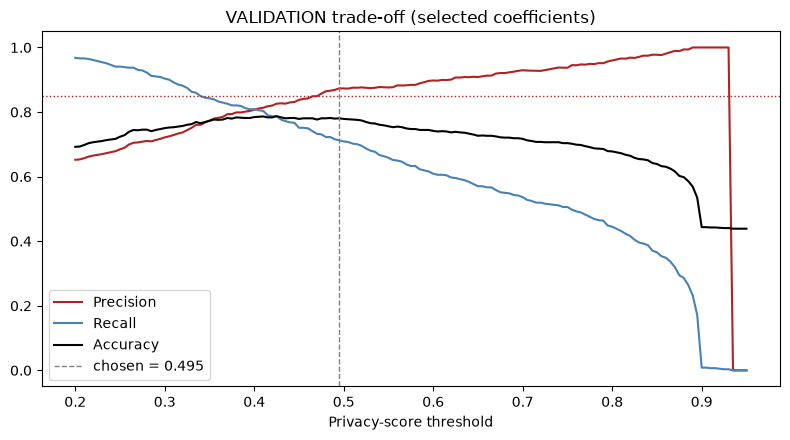

In [40]:
# Precision / recall / accuracy vs threshold on VALIDATION for the selected coefficients
_, _, _, thr_tab = find_precision_threshold(
    val_results_cache[(BEST_ALPHA, BEST_BETA, BEST_GAMMA)]["PrivacyScore"].values,
    val_results_cache[(BEST_ALPHA, BEST_BETA, BEST_GAMMA)]["TrueLabel"].values)
fig, ax = plt.subplots(figsize=(8, 4.5))
for c, col in [("Precision", "firebrick"), ("Recall", "steelblue"), ("Accuracy", "black")]:
    ax.plot(thr_tab["Threshold"], thr_tab[c], label=c, color=col)
ax.axhline(PRECISION_TARGET, ls=":", color="firebrick", lw=1)
ax.axvline(BEST_THRESHOLD, ls="--", color="grey", lw=1, label=f"chosen = {BEST_THRESHOLD:.3f}")
ax.set_xlabel("Privacy-score threshold"); ax.set_title("VALIDATION trade-off (selected coefficients)")
ax.legend(); plt.tight_layout(); plt.savefig(os.path.join(OUTPUT_DIR, "val_threshold_tradeoff.png"), dpi=120); plt.show()

## 20. Final Test Evaluation (HELD-OUT TEST SET — first and only use)

In [41]:
rl_test_results = apply_policy(BEST_Q, test_df, BEST_ALPHA, BEST_BETA, BEST_GAMMA)
rl_test_results["PrivacyClass"] = rl_test_results["PrivacyScore"].apply(privacy_class)
y_test_true = rl_test_results["TrueLabel"].values
rl_pred = (rl_test_results["PrivacyScore"].values > BEST_THRESHOLD).astype(int)

rl_metrics = classification_metrics(y_test_true, rl_pred)
rl_metrics["F0.5"] = fbeta_score(y_test_true, rl_pred, beta=0.5)
rl_metrics["ROC_AUC"] = roc_auc_score(y_test_true, rl_test_results["PrivacyScore"])
rl_metrics["AvgPrecision"] = average_precision_score(y_test_true, rl_test_results["PrivacyScore"])
rl_cm = confusion_matrix(y_test_true, rl_pred)

print(f"Validation-tuned threshold: {BEST_THRESHOLD:.3f}")
print("=== RL POLICY -- FINAL TEST METRICS ===")
for k, v in rl_metrics.items():
    print(f"  {k:12s}: {v:.4f}")
print("\nConfusion matrix (rows = true [Benign, Malicious], cols = predicted):")
print(rl_cm)
print()
print(classification_report(y_test_true, rl_pred, target_names=["Benign", "Malicious"], digits=4))

Validation-tuned threshold: 0.495
=== RL POLICY -- FINAL TEST METRICS ===
  Accuracy    : 0.7721
  Precision   : 0.8395
  Recall      : 0.7343
  F1          : 0.7834
  F0.5        : 0.8161
  ROC_AUC     : 0.8599
  AvgPrecision: 0.8969

Confusion matrix (rows = true [Benign, Malicious], cols = predicted):
[[379  83]
 [157 434]]

              precision    recall  f1-score   support

      Benign     0.7071    0.8203    0.7595       462
   Malicious     0.8395    0.7343    0.7834       591

    accuracy                         0.7721      1053
   macro avg     0.7733    0.7773    0.7715      1053
weighted avg     0.7814    0.7721    0.7729      1053



## 20b. Test-Set Uncertainty (Bootstrap 95% CIs)

In [42]:
n_boot = 2000
rng_boot = np.random.RandomState(RANDOM_STATE)
n_test = len(y_test_true)
boot = {"Accuracy": [], "Precision": [], "Recall": [], "F1": []}
for _ in range(n_boot):
    i = rng_boot.randint(0, n_test, n_test)
    m = classification_metrics(y_test_true[i], rl_pred[i])
    for k in boot:
        boot[k].append(m[k])
ci_df = pd.DataFrame({k: {"Point": rl_metrics[k], "CI_2.5%": np.percentile(v, 2.5), "CI_97.5%": np.percentile(v, 97.5)}
                      for k, v in boot.items()}).T
print(f"Bootstrap over {n_test} test apps, {n_boot} resamples:")
ci_df.round(4)

Bootstrap over 1053 test apps, 2000 resamples:


,Point,CI_2.5%,CI_97.5%
Accuracy,0.7721,0.7474,0.7968
Precision,0.8395,0.8073,0.8699
Recall,0.7343,0.6995,0.7676
F1,0.7834,0.7561,0.8090


In [43]:
rl_classification_metrics_df = pd.DataFrame([{"Model": "RL_Policy", **rl_metrics,
    "AllowRate": rl_test_results["NumAllowed"].sum() / max(rl_test_results["NumRequested"].sum(), 1)}])
rl_privacy_utility_metrics_df = pd.DataFrame([{
    "AvgPrivacyScore": rl_test_results["PrivacyScore"].mean(),
    "AvgPrivacyRisk_Individual": rl_test_results["IndividualRisk"].mean(),
    "AvgMaliciousProbability": rl_test_results["MaliciousProbability"].mean(),
    "AvgInteractionRisk": rl_test_results["InteractionRisk"].mean(),
    "AvgUtility": rl_test_results["UtilityScore"].mean(),
    "AvgPermissionsRequested": rl_test_results["NumRequested"].mean(),
    "AvgPermissionsAllowed": rl_test_results["NumAllowed"].mean(),
    "AvgPermissionsDenied": rl_test_results["NumDenied"].mean(),
    "PermissionAllowRate": rl_test_results["NumAllowed"].sum() / max(rl_test_results["NumRequested"].sum(), 1),
    "PrivacyUtilityScore": rl_test_results["UtilityScore"].mean() - rl_test_results["PrivacyScore"].mean(),
}])
display(rl_classification_metrics_df.round(4))
display(rl_privacy_utility_metrics_df.round(4))

,Model,Accuracy,Precision,Recall,F1,F0.5,ROC_AUC,AvgPrecision,AllowRate
0,RL_Policy,0.7721,0.8395,0.7343,0.7834,0.8161,0.8599,0.8969,0.0163


,AvgPrivacyScore,AvgPrivacyRisk_Individual,AvgMaliciousProbability,AvgInteractionRisk,AvgUtility,AvgPermissionsRequested,AvgPermissionsAllowed,AvgPermissionsDenied,PermissionAllowRate,PrivacyUtilityScore
0,0.5177,0.0211,0.5741,0.0,0.0003,1.981,0.0323,1.9487,0.0163,-0.5174


## 22. Privacy-Utility Analysis

In [45]:
print("Privacy class distribution on TEST (fixed 0.33 / 0.67 bands):")
print(rl_test_results["PrivacyClass"].value_counts())
print("\nMean PrivacyScore  Benign:", round(rl_test_results.loc[rl_test_results.TrueLabel == 0, "PrivacyScore"].mean(), 4),
      "| Malicious:", round(rl_test_results.loc[rl_test_results.TrueLabel == 1, "PrivacyScore"].mean(), 4))

test_with_genre = rl_test_results.assign(Genre=test_df["Category"].values, Pred=rl_pred)
per_genre = test_with_genre.groupby("Genre").apply(
    lambda d: pd.Series({"N": len(d), "Accuracy": accuracy_score(d.TrueLabel, d.Pred),
                         "Precision": precision_score(d.TrueLabel, d.Pred, zero_division=0),
                         "Recall": recall_score(d.TrueLabel, d.Pred, zero_division=0)}), include_groups=False)
print("\nPer-genre TEST metrics (informational):")
per_genre.round(4)

Privacy class distribution on TEST (fixed 0.33 / 0.67 bands):
PrivacyClass
High      379
Low       337
Medium    337
Name: count, dtype: int64

Mean PrivacyScore  Benign: 0.3232 | Malicious: 0.6698

Per-genre TEST metrics (informational):


,N,Accuracy,Precision,Recall
Genre,,,,
Arcade & Action,294.0,0.7925,0.8512,0.7989
Brain & Puzzle,280.0,0.8143,0.8795,0.8202
Cards & Casino,133.0,0.7068,0.5625,0.4186
Casual,251.0,0.7610,0.8163,0.6557
Racing,43.0,0.5814,0.8824,0.4839
Sports Games,52.0,0.8077,0.8889,0.8421
